# PENGUJIAN SARIMA vs ETS

### Pengujian SARIMA vs ETS (Menggunakan difference auto/d=None)

Long backtest: training=144 | testing=60

--- Mencari Order Optimal SARIMA pada Data Training ---
Order terbaik ditemukan: SARIMA (0, 1, 2) x (1, 0, 1, 12)

Menjalankan Walk-Forward SARIMA (60 bulan)...


c:\Users\Sulaiman\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Sulaiman\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Sulaiman\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Sulaiman\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Menjalankan Walk-Forward ETS (60 bulan)...

   HASIL EVALUASI BACKTEST 60 BULAN
SARIMA -> RMSE: 0.3321 | MAE: 0.2281
ETS    -> RMSE: 0.3894 | MAE: 0.2971

Kesimpulan: SARIMA lebih akurat pada backtest yang lebih panjang.


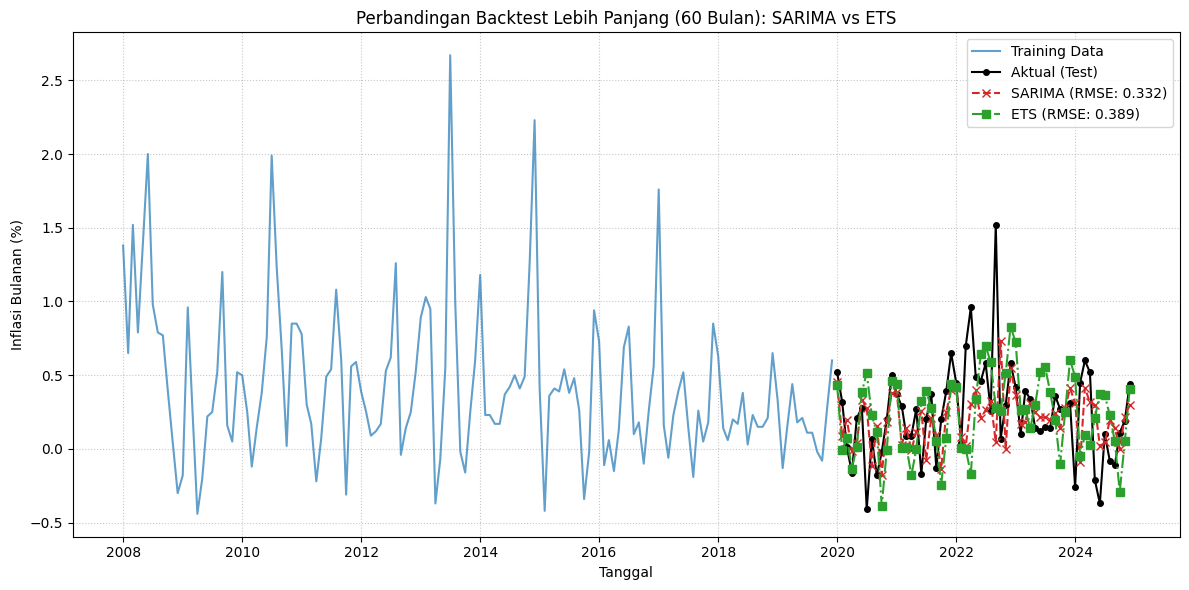

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import pmdarima as pm
from pmdarima import auto_arima
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# ==========================================
# 1. LOAD & PREPROCESS DATA INFLASI
# ==========================================
df_inflasi2 = pd.read_excel(r"C:\KULIAH\UPN\TUGAS WOK\Semester 5 bos\ADW\Inflasi Kota Surabaya Tahun 2008-2024.xlsx")

df_inflasi2['Tahun'] = df_inflasi2['Tahun'].ffill()
df_inflasi2['Tahun'] = pd.to_numeric(df_inflasi2['Tahun'], errors='raise').astype(int)

bulan_ke = {
    'januari': 1, 'februari': 2, 'maret': 3, 'april': 4,
    'mei': 5, 'juni': 6, 'juli': 7, 'agustus': 8,
    'september': 9, 'oktober': 10, 'november': 11, 'desember': 12
}

bulan_num = df_inflasi2['Bulan'].astype(str).str.strip().str.lower().map(bulan_ke)
df_inflasi2['Bulan_Num'] = bulan_num
df_inflasi2['Tanggal'] = pd.to_datetime({
    'year': df_inflasi2['Tahun'],
    'month': df_inflasi2['Bulan_Num'],
    'day': 1
})
df_inflasi2 = df_inflasi2.sort_values('Tanggal')

y = (
    df_inflasi2.sort_values('Tanggal')
    .set_index('Tanggal')['Bulanan']
    .astype(float)
)

# ==========================================
# 2. SPLIT TRAINING & TESTING (Long Backtest)
# ==========================================
n_test = 60  # 60 bulan terakhir (5 tahun)
train_long = y.iloc[:-n_test]
test_long = y.iloc[-n_test:]

print(f"Long backtest: training={len(train_long)} | testing={len(test_long)}")

# ==========================================
# 3. AUTO-ARIMA UNTUK MENDAPATKAN BEST ORDER
# ==========================================
print("\n--- Mencari Order Optimal SARIMA pada Data Training ---")
auto_model = auto_arima(
    train_long,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=None,
    seasonal=True,
    m=12,
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,
    information_criterion='bic',
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=False
)

best_order = auto_model.order
best_seasonal_order = auto_model.seasonal_order
print(f"Order terbaik ditemukan: SARIMA {best_order} x {best_seasonal_order}")

# ==========================================
# 4. SARIMA WALK-FORWARD VALIDATION
# ==========================================
history_sarima = list(train_long)
pred_sarima_long = []

print("\nMenjalankan Walk-Forward SARIMA (60 bulan)...")
for t in range(len(test_long)):
    model_kf = pm.ARIMA(order=best_order, seasonal_order=best_seasonal_order)
    fitted_sarima = model_kf.fit(history_sarima, maxiter=200, disp=False)
    yhat = fitted_sarima.predict(n_periods=1)[0]
    pred_sarima_long.append(yhat)
    history_sarima.append(test_long.iloc[t])

pred_sarima_long = pd.Series(pred_sarima_long, index=test_long.index)

# ==========================================
# 5. ETS WALK-FORWARD VALIDATION
# ==========================================
history_ets = list(train_long)
pred_ets_long = []

print("Menjalankan Walk-Forward ETS (60 bulan)...")
for t in range(len(test_long)):
    model_ets = ExponentialSmoothing(
        history_ets,
        trend='add',
        seasonal='add',
        seasonal_periods=12
    ).fit()
    yhat_ets = model_ets.forecast(steps=1)[0]
    pred_ets_long.append(yhat_ets)
    history_ets.append(test_long.iloc[t])

pred_ets_long = pd.Series(pred_ets_long, index=test_long.index)

# ==========================================
# 6. EVALUASI & METRIK PERBANDINGAN
# ==========================================
rmse_sarima_long = root_mean_squared_error(test_long, pred_sarima_long)
mae_sarima_long = mean_absolute_error(test_long, pred_sarima_long)

rmse_ets_long = root_mean_squared_error(test_long, pred_ets_long)
mae_ets_long = mean_absolute_error(test_long, pred_ets_long)

print("\n==========================================")
print("   HASIL EVALUASI BACKTEST 60 BULAN")
print("==========================================")
print(f"SARIMA -> RMSE: {rmse_sarima_long:.4f} | MAE: {mae_sarima_long:.4f}")
print(f"ETS    -> RMSE: {rmse_ets_long:.4f} | MAE: {mae_ets_long:.4f}")

if rmse_sarima_long < rmse_ets_long:
    print("\nKesimpulan: SARIMA lebih akurat pada backtest yang lebih panjang.")
elif rmse_ets_long < rmse_sarima_long:
    print("\nKesimpulan: ETS lebih akurat pada backtest yang lebih panjang.")
else:
    print("\nKesimpulan: Keduanya setara pada backtest yang lebih panjang.")

# ==========================================
# 7. VISUALISASI HASIL PERBANDINGAN
# ==========================================
plt.figure(figsize=(12, 6))
# Menampilkan seluruh data training tanpa dibatasi [-36:]
plt.plot(train_long.index, train_long, label="Training Data", color='tab:blue', alpha=0.7)
plt.plot(test_long.index, test_long, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(pred_sarima_long.index, pred_sarima_long, label=f"SARIMA (RMSE: {rmse_sarima_long:.3f})", color="tab:red", linestyle='--', marker='x')
plt.plot(pred_ets_long.index, pred_ets_long, label=f"ETS (RMSE: {rmse_ets_long:.3f})", color="tab:green", linestyle='-.', marker='s')

plt.title("Perbandingan Backtest Lebih Panjang (60 Bulan): SARIMA vs ETS")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

### Visualisasi Tahun yang Diprediksi

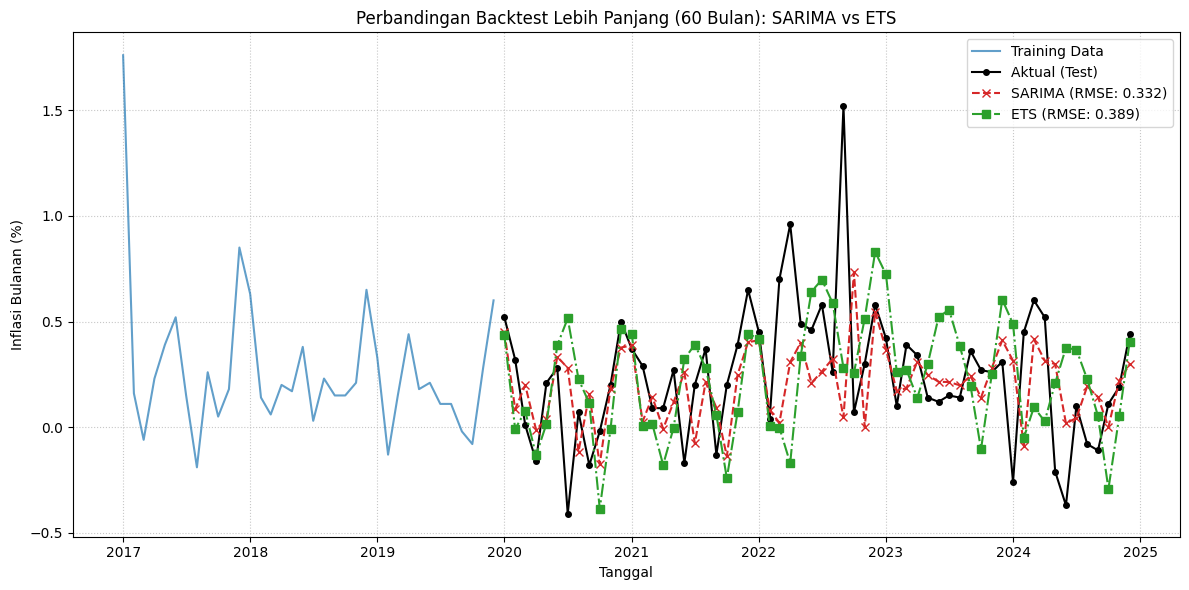

In [2]:
# ==========================================
# 7. VISUALISASI HASIL PERBANDINGAN
# ==========================================
plt.figure(figsize=(12, 6))
plt.plot(train_long.index[-36:], train_long.iloc[-36:], label="Training Data", color='tab:blue', alpha=0.7)
plt.plot(test_long.index, test_long, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(pred_sarima_long.index, pred_sarima_long, label=f"SARIMA (RMSE: {rmse_sarima_long:.3f})", color="tab:red", linestyle='--', marker='x')
plt.plot(pred_ets_long.index, pred_ets_long, label=f"ETS (RMSE: {rmse_ets_long:.3f})", color="tab:green", linestyle='-.', marker='s')

plt.title("Perbandingan Backtest Lebih Panjang (60 Bulan): SARIMA vs ETS")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

### Pengujian SARIMA vs ETS (Menggunakan difference 0/d=0)

Long backtest: training=144 | testing=60

--- Uji Stasioneritas ADF pada Data Training ---
ADF Statistic : -4.7306
p-value       : 0.0001
Kesimpulan: Data training stasioner (Valid menggunakan d=0)

--- Mencari Order Optimal SARIMA pada Data Training ---
Order terbaik ditemukan: SARIMA (0, 0, 1) x (0, 0, 0, 12)

Menjalankan Walk-Forward SARIMA (60 bulan)...
Menjalankan Walk-Forward ETS (60 bulan)...

    HASIL EVALUASI BACKTEST 60 BULAN
SARIMA -> RMSE: 0.3360 | MAE: 0.2377
ETS    -> RMSE: 0.3894 | MAE: 0.2971

Kesimpulan: SARIMA lebih akurat pada backtest yang lebih panjang.


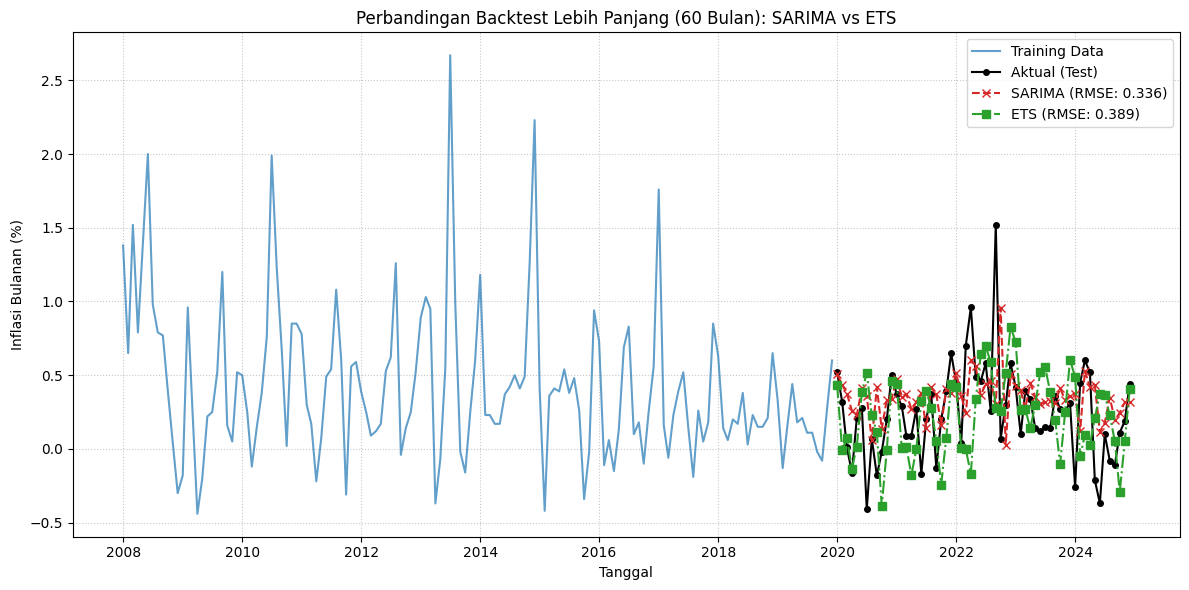

In [3]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import pmdarima as pm
from pmdarima import auto_arima
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# ==========================================
# 1. LOAD & PREPROCESS DATA INFLASI
# ==========================================
df_inflasi = pd.read_excel(r"C:\KULIAH\UPN\TUGAS WOK\Semester 5 bos\ADW\Inflasi Kota Surabaya Tahun 2008-2024.xlsx")

df_inflasi['Tahun'] = df_inflasi['Tahun'].ffill()
df_inflasi['Tahun'] = pd.to_numeric(df_inflasi['Tahun'], errors='raise').astype(int)

bulan_ke = {
    'januari': 1, 'februari': 2, 'maret': 3, 'april': 4,
    'mei': 5, 'juni': 6, 'juli': 7, 'agustus': 8,
    'september': 9, 'oktober': 10, 'november': 11, 'desember': 12
}

bulan_num = df_inflasi['Bulan'].astype(str).str.strip().str.lower().map(bulan_ke)
df_inflasi['Bulan_Num'] = bulan_num
df_inflasi['Tanggal'] = pd.to_datetime({
    'year': df_inflasi['Tahun'],
    'month': df_inflasi['Bulan_Num'],
    'day': 1
})
df_inflasi = df_inflasi.sort_values('Tanggal')

y = (
    df_inflasi.sort_values('Tanggal')
    .set_index('Tanggal')['Bulanan']
    .astype(float)
)

# ==========================================
# 2. SPLIT TRAINING & TESTING (Long Backtest)
# ==========================================
n_test2 = 60  # 60 bulan terakhir (5 tahun)
train_long2 = y.iloc[:-n_test2]
test_long2 = y.iloc[-n_test2:]

print(f"Long backtest: training={len(train_long2)} | testing={len(test_long2)}")

# ==========================================
# 3. UJI STASIONERITAS (ADF TEST) UNTUK VALIDASI d=0
# ==========================================
print("\n--- Uji Stasioneritas ADF pada Data Training ---")
adf_result = adfuller(train_long2.dropna())
print(f"ADF Statistic : {adf_result[0]:.4f}")
print(f"p-value       : {adf_result[1]:.4f}")

if adf_result[1] < 0.05:
    print("Kesimpulan: Data training stasioner (Valid menggunakan d=0)")
else:
    print("Kesimpulan: Data training tidak stasioner (Pertimbangkan d=None atau d=1)")

# ==========================================
# 4. AUTO-ARIMA UNTUK MENDAPATKAN BEST ORDER
# ==========================================
print("\n--- Mencari Order Optimal SARIMA pada Data Training ---")
auto_model = auto_arima(
    train_long2,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=0,             # Hasil ADF menunjukkan data stasioner, sehingga d=0
    seasonal=True,
    m=12,
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,
    information_criterion='bic',
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=False
)

best_order = auto_model.order
best_seasonal_order = auto_model.seasonal_order
print(f"Order terbaik ditemukan: SARIMA {best_order} x {best_seasonal_order}")

# ==========================================
# 5. SARIMA WALK-FORWARD VALIDATION
# ==========================================
history_sarima = list(train_long)
pred_sarima_long = []

print("\nMenjalankan Walk-Forward SARIMA (60 bulan)...")
for t in range(len(test_long)):
    model_kf = pm.ARIMA(order=best_order, seasonal_order=best_seasonal_order)
    fitted_sarima = model_kf.fit(history_sarima, maxiter=200, disp=False)
    yhat = fitted_sarima.predict(n_periods=1)[0]
    pred_sarima_long.append(yhat)
    history_sarima.append(test_long.iloc[t])

pred_sarima_long = pd.Series(pred_sarima_long, index=test_long.index)

# ==========================================
# 6. ETS WALK-FORWARD VALIDATION
# ==========================================
history_ets = list(train_long)
pred_ets_long = []

print("Menjalankan Walk-Forward ETS (60 bulan)...")
for t in range(len(test_long)):
    model_ets = ExponentialSmoothing(
        history_ets,
        trend='add',
        seasonal='add',
        seasonal_periods=12
    ).fit()
    yhat_ets = model_ets.forecast(steps=1)[0]
    pred_ets_long.append(yhat_ets)
    history_ets.append(test_long.iloc[t])

pred_ets_long = pd.Series(pred_ets_long, index=test_long.index)

# ==========================================
# 7. EVALUASI & METRIK PERBANDINGAN
# ==========================================
rmse_sarima_long = root_mean_squared_error(test_long, pred_sarima_long)
mae_sarima_long = mean_absolute_error(test_long, pred_sarima_long)

rmse_ets_long = root_mean_squared_error(test_long, pred_ets_long)
mae_ets_long = mean_absolute_error(test_long, pred_ets_long)

print("\n==========================================")
print("    HASIL EVALUASI BACKTEST 60 BULAN")
print("==========================================")
print(f"SARIMA -> RMSE: {rmse_sarima_long:.4f} | MAE: {mae_sarima_long:.4f}")
print(f"ETS    -> RMSE: {rmse_ets_long:.4f} | MAE: {mae_ets_long:.4f}")

if rmse_sarima_long < rmse_ets_long:
    print("\nKesimpulan: SARIMA lebih akurat pada backtest yang lebih panjang.")
elif rmse_ets_long < rmse_sarima_long:
    print("\nKesimpulan: ETS lebih akurat pada backtest yang lebih panjang.")
else:
    print("\nKesimpulan: Keduanya setara pada backtest yang lebih panjang.")

# ==========================================
# 8. VISUALISASI HASIL PERBANDINGAN
# ==========================================
plt.figure(figsize=(12, 6))
plt.plot(train_long.index, train_long, label="Training Data", color='tab:blue', alpha=0.7)
plt.plot(test_long.index, test_long, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(pred_sarima_long.index, pred_sarima_long, label=f"SARIMA (RMSE: {rmse_sarima_long:.3f})", color="tab:red", linestyle='--', marker='x')
plt.plot(pred_ets_long.index, pred_ets_long, label=f"ETS (RMSE: {rmse_ets_long:.3f})", color="tab:green", linestyle='-.', marker='s')

plt.title("Perbandingan Backtest Lebih Panjang (60 Bulan): SARIMA vs ETS")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

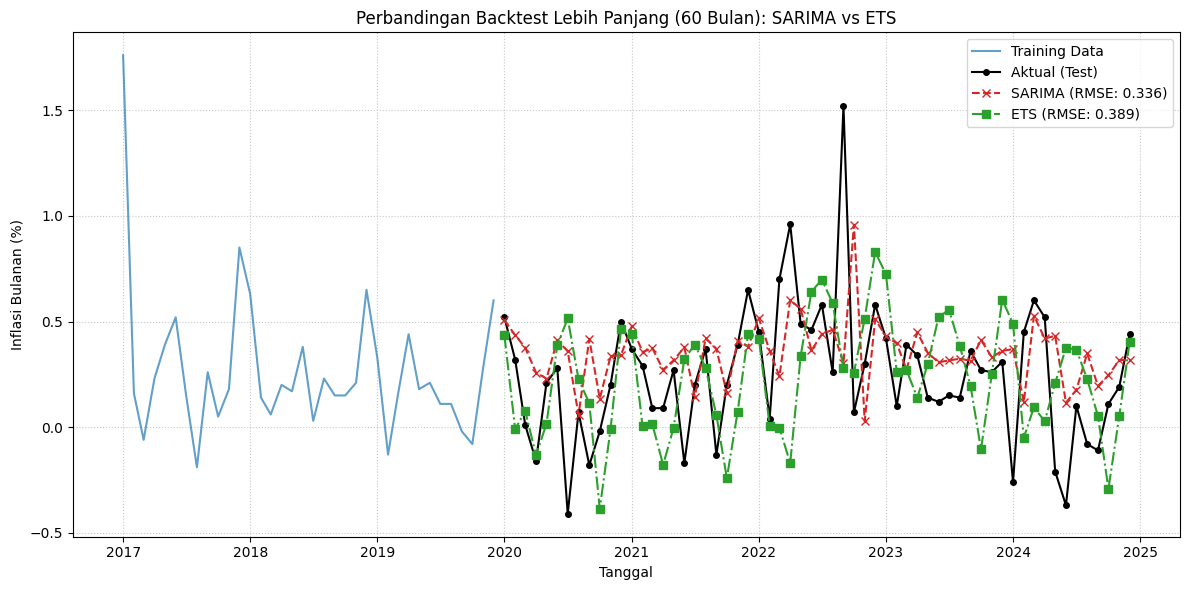

In [4]:
# ==========================================
# 7. VISUALISASI HASIL PERBANDINGAN
# ==========================================
plt.figure(figsize=(12, 6))
plt.plot(train_long2.index[-36:], train_long2.iloc[-36:], label="Training Data", color='tab:blue', alpha=0.7)
plt.plot(test_long2.index, test_long2, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(pred_sarima_long.index, pred_sarima_long, label=f"SARIMA (RMSE: {rmse_sarima_long:.3f})", color="tab:red", linestyle='--', marker='x')
plt.plot(pred_ets_long.index, pred_ets_long, label=f"ETS (RMSE: {rmse_ets_long:.3f})", color="tab:green", linestyle='-.', marker='s')

plt.title("Perbandingan Backtest Lebih Panjang (60 Bulan): SARIMA vs ETS")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

Dalam dua jenis pengujian ini saya menggunakan dua jenis "Degree of Differencing" / d yang berbeda. Dimana pada 'Pengujian SARIMA vs ETS (Menggunakan difference 0/d=0)', berdasarkan uji stationeritas ADF menunjukkan data bersifat stationer sehingga d=0. Sedangkan pada 'Pengujian SARIMA vs ETS (Menggunakan difference auto/d=None)', berdasarkan uji stationeritas yang dilakukan otomatis oleh logika 'auto_arima' dimana mencari yang terbaik dari beberapa uji seperti KPSS, ADF, dan PP menujukkan data bersifat tidak stationer dengan d=1.   

Karena pada 'Pengujian SARIMA vs ETS (Menggunakan difference auto/d=None)' menghasilkan 'rmse' SARIMA dengan nilai yang lebih kecil dari 'rmse' SARIMA pada 'Pengujian SARIMA vs ETS (Menggunakan difference 0/d=0)', saya menggunakan uji perbandingan pada 'Pengujian SARIMA vs ETS (Menggunakan difference auto/d=None)' dengan nilai rmse sarima sebesar 0.3321 dan 0.3360 berurutan.

# Uji Coba Model SARIMA untuk Prediksi Tahun Kedepan

Tanggal data terakhir: 2024-12-01 00:00:00
Rentang prediksi: 2026-01-01 00:00:00 sampai 2028-12-01 00:00:00


,SARIMA,ETS
2026-01-01,0.245447,0.264516
2026-02-01,0.201518,-0.076072
2026-03-01,0.271138,-0.019015
2026-04-01,0.272561,-0.160186
2026-05-01,0.166078,-0.101953
2026-06-01,0.146307,0.104514
2026-07-01,0.199493,0.222750
2026-08-01,0.171191,0.120986
2026-09-01,0.223656,0.004517
2026-10-01,0.158551,-0.279600


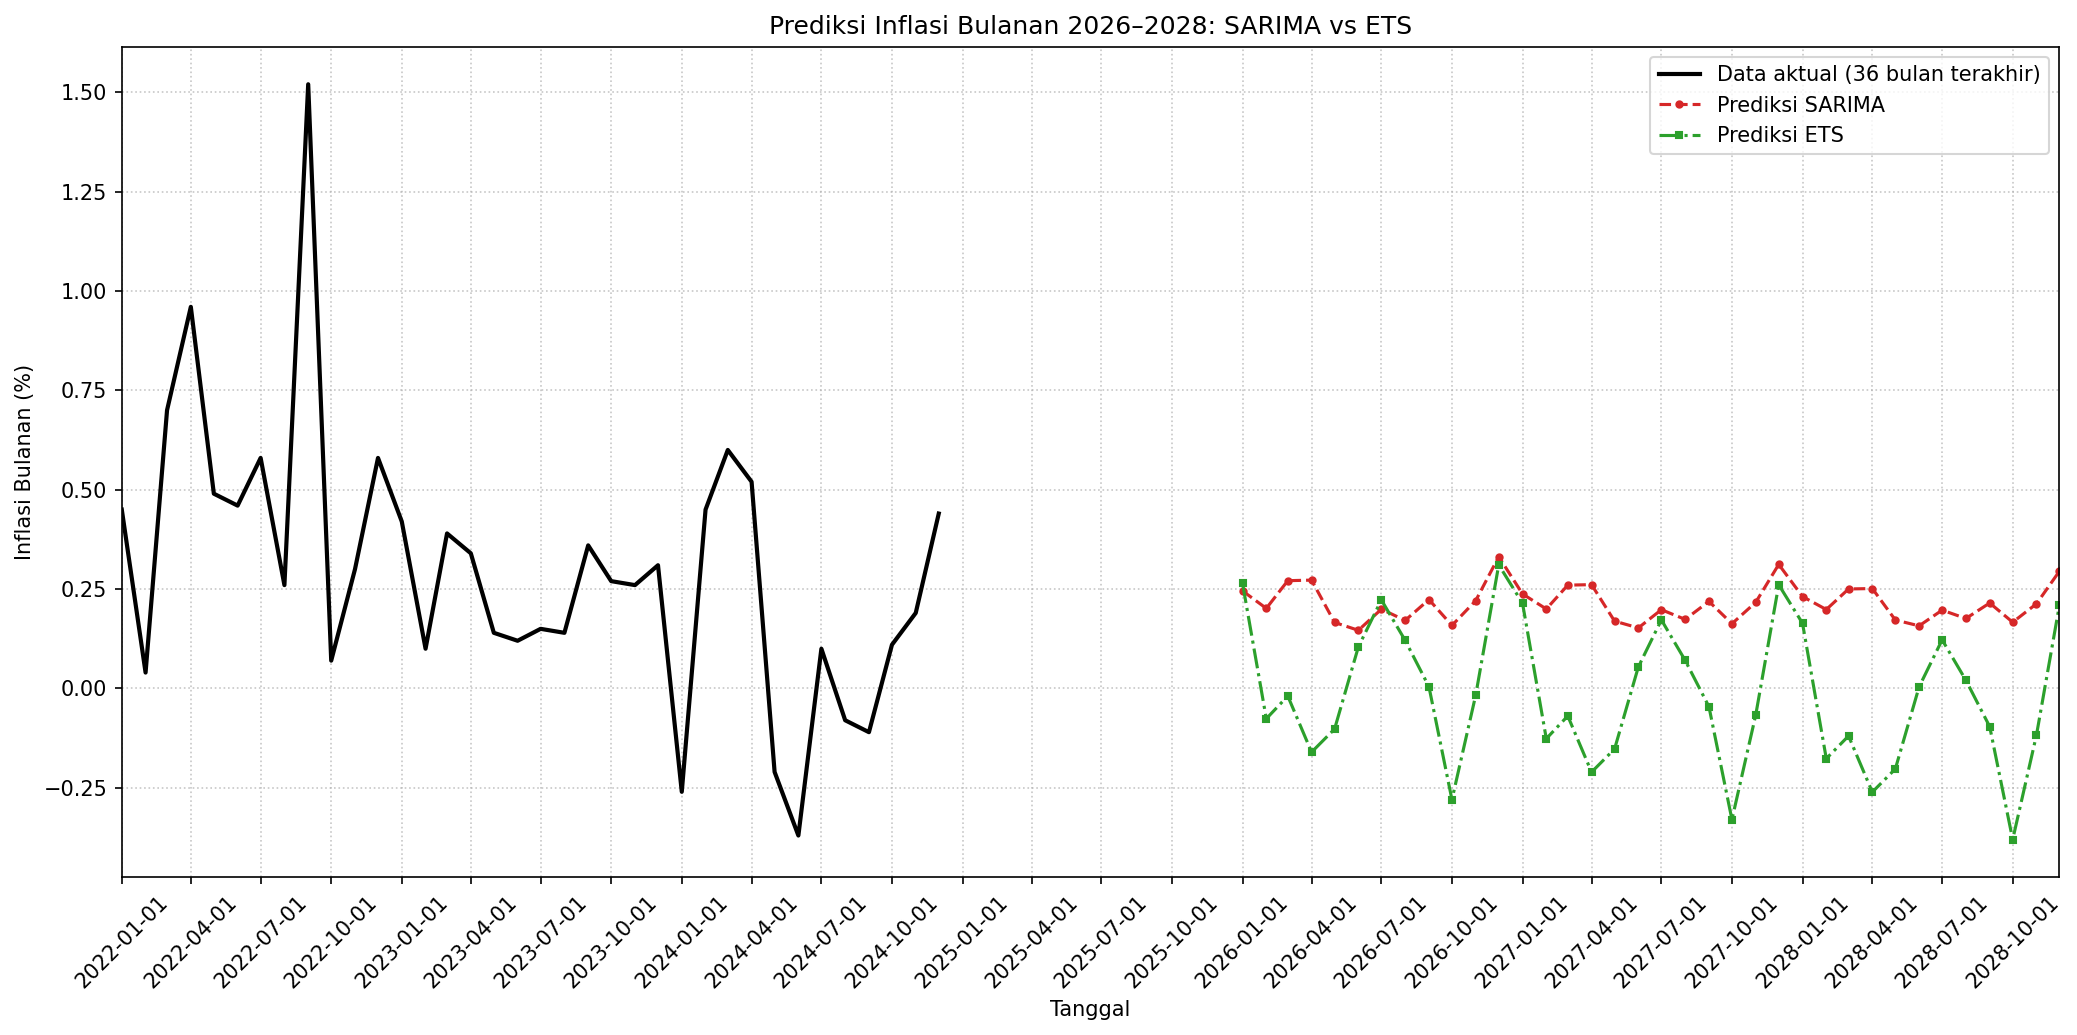

In [5]:
# Forecast SARIMA dan ETS untuk 2026–2028
forecast_start = pd.Timestamp("2026-01-01")
forecast_end = pd.Timestamp("2028-12-01")

y_forecast = y.dropna().sort_index()
last_date = y_forecast.index[-1]

if last_date >= forecast_end:
    raise ValueError("Data terakhir sudah mencapai atau melewati Desember 2028.")

# Perlu memprediksi periode perantara agar mencapai Januari 2026
forecast_dates_all = pd.date_range(
    start=last_date + pd.offsets.MonthBegin(1),
    end=forecast_end,
    freq="MS"
)
n_steps = len(forecast_dates_all)

# SARIMA: pemilihan orde otomatis, termasuk d
sarima_forecast_model = auto_arima(
    y_forecast,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=None,
    seasonal=True,
    m=12,
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,
    information_criterion="bic",
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=False
)
sarima_predictions = sarima_forecast_model.predict(n_periods=n_steps)

# ETS
ets_forecast_model = ExponentialSmoothing(
    y_forecast,
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

ets_predictions = ets_forecast_model.forecast(n_steps)

# Ambil prediksi 2026–2028
forecast_results = pd.DataFrame(
    {
        "SARIMA": np.asarray(sarima_predictions),
        "ETS": np.asarray(ets_predictions)
    },
    index=forecast_dates_all
).loc[forecast_start:forecast_end]


print("Tanggal data terakhir:", y_forecast.index[-1])
print("Rentang prediksi:", forecast_results.index.min(),
      "sampai", forecast_results.index.max())
display(forecast_results)

# Plot data aktual dan prediksi
plt.figure(figsize=(14, 7), dpi=150)

plt.plot(
    y_forecast.index[-36:],
    y_forecast.iloc[-36:],
    label="Data aktual (36 bulan terakhir)",
    color="black",
    linewidth=2
)

plt.plot(
    forecast_results.index,
    forecast_results["SARIMA"],
    label="Prediksi SARIMA",
    linestyle="--",
    marker="o",
    markersize=3,
    color="tab:red"
)

plt.plot(
    forecast_results.index,
    forecast_results["ETS"],
    label="Prediksi ETS",
    linestyle="-.",
    marker="s",
    markersize=3,
    color="tab:green"
)

plt.xlim(y_forecast.index[-36], forecast_end)
plt.xticks(
    pd.date_range(
        start=y_forecast.index[-36],
        end=forecast_end,
        freq="3MS"
    ),
    rotation=45
)

plt.title("Prediksi Inflasi Bulanan 2026–2028: SARIMA vs ETS")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.7)
plt.tight_layout()
plt.show()